# SentinelX — Cybersecurity Threat Detection Dashboard

**Submitted by:** Gunjan Saini  
**Bootcamp:** IBM SkillsBuild Cybersecurity Bootcamp, October 2026 (BharatCares)  
**Tech Stack:** Python · Pandas · Matplotlib  

---

## Project Overview

SentinelX simulates a **Security Operations Centre (SOC) dashboard** that:
- Generates synthetic security events (fictional users and RFC 5737 documentation IPs — never real)
- Detects **brute-force login attacks** using a configurable time-windowed rule grouped by source IP
- Raises actionable alerts with plain-English explanations and recommended defensive actions
- Visualises events by severity and type using charts

> ⚠️ **Safety Notice:** All data is synthetic. No real networks are scanned, no real credentials are used,
> and no data is sent to any external service. IP addresses use RFC 5737 documentation ranges.

---
## 1. Configuration
Adjust the detection rule parameters here without touching any other code.

In [23]:
# ── Detection Rule Configuration ─────────────────────────────────────────
# How many failed logins from the same source IP within the time window
# are required before an alert is raised.
BRUTE_FORCE_THRESHOLD = 5

# How many minutes to look back when counting failed logins.
BRUTE_FORCE_WINDOW_MINUTES = 10

print(f"Configuration loaded:")
print(f"  Brute-force threshold : {BRUTE_FORCE_THRESHOLD} failures")
print(f"  Detection window      : {BRUTE_FORCE_WINDOW_MINUTES} minutes")

Configuration loaded:
  Brute-force threshold : 5 failures
  Detection window      : 10 minutes


---
## 2. Imports

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from datetime import datetime, timedelta, timezone
from collections import defaultdict

print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## 3. Synthetic Security Events

All events are generated here. The dataset is designed to exercise the detection logic:
- **Cluster A:** 6 `LOGIN_FAILURE` events from `192.0.2.42` within 9 minutes → **should trigger alert**
- **Cluster B:** 3 `LOGIN_FAILURE` events from `198.51.100.7` within 12 minutes → below threshold, no alert
- **Older events:** 2 failures from `192.0.2.42` at 29–30 minutes ago → outside window, ignored
- Plus: successful logins, port scans, privilege escalation, suspicious traffic

In [25]:
now = datetime.now(timezone.utc)

def mins_ago(m):
    """Return a UTC datetime m minutes in the past."""
    return now - timedelta(minutes=m)

# Each event: (id, timestamp, username, source_ip, event_type, severity, description)
raw_events = [
    # ── Cluster A: 6 failures from 192.0.2.42 (within window) → triggers alert
    (1,  mins_ago(9),  "alice",   "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user alice from 192.0.2.42"),
    (2,  mins_ago(8),  "alice",   "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user alice from 192.0.2.42"),
    (3,  mins_ago(7),  "alice",   "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user alice from 192.0.2.42"),
    (4,  mins_ago(6),  "alice",   "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user alice from 192.0.2.42"),
    (5,  mins_ago(5),  "alice",   "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user alice from 192.0.2.42"),
    (6,  mins_ago(4),  "alice",   "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user alice from 192.0.2.42"),
    # ── Cluster B: 3 failures from 198.51.100.7 (below threshold)
    (7,  mins_ago(12), "bob",     "198.51.100.7",   "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user bob from 198.51.100.7"),
    (8,  mins_ago(11), "bob",     "198.51.100.7",   "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user bob from 198.51.100.7"),
    (9,  mins_ago(10), "bob",     "198.51.100.7",   "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user bob from 198.51.100.7"),
    # ── Successful logins
    (10, mins_ago(3),  "carol",   "192.0.2.10",     "LOGIN_SUCCESS",       "LOW",      "Successful login for user carol from 192.0.2.10"),
    (11, mins_ago(2),  "dave",    "198.51.100.20",  "LOGIN_SUCCESS",       "LOW",      "Successful login for user dave from 198.51.100.20"),
    (12, mins_ago(1),  "eve",     "192.0.2.55",     "LOGIN_SUCCESS",       "LOW",      "Successful login for user eve from 192.0.2.55"),
    # ── Port scans
    (13, mins_ago(25), "unknown", "192.0.2.99",     "PORT_SCAN",           "HIGH",     "Port scan detected from 192.0.2.99 targeting ports 22, 80, 443, 8080"),
    (14, mins_ago(20), "unknown", "198.51.100.50",  "PORT_SCAN",           "MEDIUM",   "Port scan detected from 198.51.100.50 targeting ports 3306, 5432"),
    # ── Privilege escalation
    (15, mins_ago(18), "frank",   "192.0.2.77",     "PRIVILEGE_ESCALATION","CRITICAL", "Privilege escalation attempt by frank from 192.0.2.77 — sudo abuse detected"),
    (16, mins_ago(15), "grace",   "198.51.100.88",  "PRIVILEGE_ESCALATION","HIGH",     "Privilege escalation attempt by grace from 198.51.100.88"),
    # ── Suspicious traffic
    (17, mins_ago(28), "unknown", "192.0.2.200",    "SUSPICIOUS_TRAFFIC",  "MEDIUM",   "Unusual outbound traffic volume detected from 192.0.2.200"),
    (18, mins_ago(22), "unknown", "198.51.100.101", "SUSPICIOUS_TRAFFIC",  "LOW",      "Repeated DNS lookups for unusual domains from 198.51.100.101"),
    (19, mins_ago(16), "heidi",   "192.0.2.33",     "SUSPICIOUS_TRAFFIC",  "MEDIUM",   "Suspicious traffic pattern from heidi at 192.0.2.33 — possible data exfiltration"),
    # ── Older events (outside window — should NOT count toward brute-force)
    (20, mins_ago(30), "ivan",    "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user ivan from 192.0.2.42 (outside window)"),
    (21, mins_ago(29), "judy",    "192.0.2.42",     "LOGIN_FAILURE",       "HIGH",     "Failed login attempt for user judy from 192.0.2.42 (outside window)"),
    # ── Mixed additional events
    (22, mins_ago(27), "karl",    "198.51.100.3",   "LOGIN_SUCCESS",       "LOW",      "Successful login for user karl from 198.51.100.3"),
    (23, mins_ago(26), "lena",    "192.0.2.14",     "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user lena from 192.0.2.14"),
    (24, mins_ago(24), "mike",    "198.51.100.9",   "LOGIN_SUCCESS",       "LOW",      "Successful login for user mike from 198.51.100.9"),
    (25, mins_ago(23), "nina",    "192.0.2.61",     "PORT_SCAN",           "MEDIUM",   "Port scan detected from 192.0.2.61 targeting ports 21, 23, 25"),
    (26, mins_ago(21), "oscar",   "198.51.100.77",  "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user oscar from 198.51.100.77"),
    (27, mins_ago(19), "paul",    "192.0.2.5",      "SUSPICIOUS_TRAFFIC",  "LOW",      "Low-level suspicious traffic from 192.0.2.5"),
    (28, mins_ago(17), "quinn",   "198.51.100.44",  "LOGIN_SUCCESS",       "LOW",      "Successful login for user quinn from 198.51.100.44"),
    (29, mins_ago(14), "ruth",    "192.0.2.88",     "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user ruth from 192.0.2.88"),
    (30, mins_ago(13), "sam",     "198.51.100.60",  "PRIVILEGE_ESCALATION","HIGH",     "Privilege escalation attempt by sam from 198.51.100.60"),
    (31, mins_ago(8),  "tina",    "192.0.2.111",    "LOGIN_SUCCESS",       "LOW",      "Successful login for user tina from 192.0.2.111"),
    (32, mins_ago(7),  "uma",     "198.51.100.55",  "SUSPICIOUS_TRAFFIC",  "MEDIUM",   "Suspicious traffic pattern from uma at 198.51.100.55"),
    (33, mins_ago(6),  "victor",  "192.0.2.78",     "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user victor from 192.0.2.78"),
    (34, mins_ago(5),  "wendy",   "198.51.100.22",  "LOGIN_SUCCESS",       "LOW",      "Successful login for user wendy from 198.51.100.22"),
    (35, mins_ago(4),  "xavier",  "192.0.2.19",     "PORT_SCAN",           "HIGH",     "Port scan detected from 192.0.2.19 targeting a wide port range"),
    (36, mins_ago(3),  "yara",    "198.51.100.33",  "LOGIN_FAILURE",       "MEDIUM",   "Failed login attempt for user yara from 198.51.100.33"),
    (37, mins_ago(2),  "zoe",     "192.0.2.91",     "LOGIN_SUCCESS",       "LOW",      "Successful login for user zoe from 192.0.2.91"),
    (38, mins_ago(1),  "alice",   "192.0.2.42",     "LOGIN_SUCCESS",       "LOW",      "Successful login for user alice from 192.0.2.42 (finally succeeded)"),
]

# Build a DataFrame
df = pd.DataFrame(raw_events, columns=[
    "id", "timestamp", "username", "source_ip",
    "event_type", "severity", "description"
])

print(f"Loaded {len(df)} synthetic security events.")
print(f"Event types : {sorted(df['event_type'].unique())}")
print(f"Severities  : {sorted(df['severity'].unique())}")

Loaded 38 synthetic security events.
Event types : ['LOGIN_FAILURE', 'LOGIN_SUCCESS', 'PORT_SCAN', 'PRIVILEGE_ESCALATION', 'SUSPICIOUS_TRAFFIC']
Severities  : ['CRITICAL', 'HIGH', 'LOW', 'MEDIUM']


---
## 4. Event Preview (newest first)

In [26]:
# Show all events sorted newest first
df_display = df.sort_values("timestamp", ascending=False).reset_index(drop=True)
df_display["timestamp"] = df_display["timestamp"].dt.strftime("%d %b %Y %H:%M:%S UTC")
df_display[["id", "timestamp", "username", "source_ip", "event_type", "severity"]]

,id,timestamp,username,source_ip,event_type,severity
0,38,25 Oct 2026 19:47:49 UTC,alice,192.0.2.42,LOGIN_SUCCESS,LOW
1,12,25 Oct 2026 19:47:49 UTC,eve,192.0.2.55,LOGIN_SUCCESS,LOW
2,37,25 Oct 2026 19:46:49 UTC,zoe,192.0.2.91,LOGIN_SUCCESS,LOW
3,11,25 Oct 2026 19:46:49 UTC,dave,198.51.100.20,LOGIN_SUCCESS,LOW
4,36,25 Oct 2026 19:45:49 UTC,yara,198.51.100.33,LOGIN_FAILURE,MEDIUM
5,10,25 Oct 2026 19:45:49 UTC,carol,192.0.2.10,LOGIN_SUCCESS,LOW
6,6,25 Oct 2026 19:44:49 UTC,alice,192.0.2.42,LOGIN_FAILURE,HIGH
7,35,25 Oct 2026 19:44:49 UTC,xavier,192.0.2.19,PORT_SCAN,HIGH
8,5,25 Oct 2026 19:43:49 UTC,alice,192.0.2.42,LOGIN_FAILURE,HIGH
9,34,25 Oct 2026 19:43:49 UTC,wendy,198.51.100.22,LOGIN_SUCCESS,LOW


---
## 5. Dashboard Summary

In [27]:
severity_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
severity_counts = df["severity"].value_counts().reindex(severity_order, fill_value=0)

print("=" * 45)
print("   SENTINELX — DASHBOARD SUMMARY")
print("=" * 45)
print(f"  Total Events      : {len(df)}")
print("-" * 45)
for sev in severity_order:
    print(f"  {sev:<18}: {severity_counts[sev]}")
print("=" * 45)

   SENTINELX — DASHBOARD SUMMARY
  Total Events      : 38
---------------------------------------------
  LOW               : 12
  MEDIUM            : 13
  HIGH              : 12
  CRITICAL          : 1


---
## 6. Event Filtering
Filter events by severity and/or event type — mirrors the dashboard dropdown filters.

In [28]:
def filter_events(df, severity=None, event_type=None):
    """
    Filter events by severity and/or event_type.
    Pass None to skip a filter (returns all).
    """
    result = df.copy()
    if severity:
        severity = severity.upper()
        valid = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
        if severity not in valid:
            raise ValueError(f"Invalid severity '{severity}'. Valid: {valid}")
        result = result[result["severity"] == severity]
    if event_type:
        event_type = event_type.upper()
        valid_types = ["LOGIN_FAILURE", "LOGIN_SUCCESS", "PORT_SCAN",
                       "PRIVILEGE_ESCALATION", "SUSPICIOUS_TRAFFIC"]
        if event_type not in valid_types:
            raise ValueError(f"Invalid event_type '{event_type}'. Valid: {valid_types}")
        result = result[result["event_type"] == event_type]
    return result.sort_values("timestamp", ascending=False).reset_index(drop=True)

# ── Example: show only HIGH severity LOGIN_FAILURE events
filtered = filter_events(df, severity="HIGH", event_type="LOGIN_FAILURE")
print(f"HIGH severity LOGIN_FAILURE events: {len(filtered)}")
filtered[["id", "username", "source_ip", "event_type", "severity"]]

HIGH severity LOGIN_FAILURE events: 8


,id,username,source_ip,event_type,severity
0,6,alice,192.0.2.42,LOGIN_FAILURE,HIGH
1,5,alice,192.0.2.42,LOGIN_FAILURE,HIGH
2,4,alice,192.0.2.42,LOGIN_FAILURE,HIGH
3,3,alice,192.0.2.42,LOGIN_FAILURE,HIGH
4,2,alice,192.0.2.42,LOGIN_FAILURE,HIGH
5,1,alice,192.0.2.42,LOGIN_FAILURE,HIGH
6,21,judy,192.0.2.42,LOGIN_FAILURE,HIGH
7,20,ivan,192.0.2.42,LOGIN_FAILURE,HIGH


---
## 7. Brute-Force Detection Rule

**Algorithm:**
1. Keep only `LOGIN_FAILURE` events — successful logins are completely ignored
2. Keep only events within the last `BRUTE_FORCE_WINDOW_MINUTES` minutes
3. Group by `source_ip`
4. If any IP has **≥ BRUTE_FORCE_THRESHOLD** failures → raise an Alert

In [29]:
def detect_brute_force(df, threshold=BRUTE_FORCE_THRESHOLD,
                        window_minutes=BRUTE_FORCE_WINDOW_MINUTES):
    """
    Detect brute-force login attacks.

    Returns a list of alert dicts, one per offending IP.
    Each alert contains:
      - source_ip        : the IP that triggered the alert
      - affected_users   : comma-separated list of targeted usernames
      - failure_count    : number of failures within the window
      - severity         : always HIGH for this rule
      - rule_name        : BRUTE_FORCE_LOGIN
      - explanation      : plain-English description
      - recommended_action : what a defender should do
    """
    window_start = datetime.now(timezone.utc) - timedelta(minutes=window_minutes)

    # Step 1 + 2: filter to LOGIN_FAILURE within the time window
    failures = df[
        (df["event_type"] == "LOGIN_FAILURE") &
        (df["timestamp"] >= window_start)
    ]

    # Step 3: group by source IP
    grouped = failures.groupby("source_ip")

    alerts = []
    for ip, group in grouped:
        count = len(group)
        # Step 4: check threshold
        if count >= threshold:
            users = ", ".join(sorted(group["username"].unique()))
            explanation = (
                f"Brute-force attack detected: {count} failed login attempt"
                f"{'s' if count != 1 else ''} from IP {ip} within the last "
                f"{window_minutes} minute{'s' if window_minutes != 1 else ''}, "
                f"targeting account{'s' if ',' in users else ''}: {users}."
            )
            recommended_action = (
                f"Block or rate-limit IP {ip} at the firewall. "
                f"Force a password reset for: {users}. "
                f"Enable multi-factor authentication (MFA) to prevent future attacks."
            )
            alerts.append({
                "rule_name": "BRUTE_FORCE_LOGIN",
                "source_ip": ip,
                "affected_users": users,
                "failure_count": count,
                "severity": "HIGH",
                "explanation": explanation,
                "recommended_action": recommended_action,
            })
    return alerts


alerts = detect_brute_force(df)
print(f"Alerts raised: {len(alerts)}")

Alerts raised: 1


---
## 8. Active Alerts

In [30]:
if not alerts:
    print("✓ No active alerts detected.")
else:
    for i, alert in enumerate(alerts, 1):
        print("=" * 60)
        print(f"  ALERT #{i}  [{alert['severity']}]  {alert['rule_name']}")
        print("=" * 60)
        print(f"  Source IP      : {alert['source_ip']}")
        print(f"  Targeted Users : {alert['affected_users']}")
        print(f"  Failure Count  : {alert['failure_count']}")
        print(f"  Severity       : {alert['severity']}")
        print()
        print(f"  Explanation:")
        print(f"    {alert['explanation']}")
        print()
        print(f"  Recommended Action:")
        print(f"    {alert['recommended_action']}")
        print()

  ALERT #1  [HIGH]  BRUTE_FORCE_LOGIN
  Source IP      : 192.0.2.42
  Targeted Users : alice
  Failure Count  : 6
  Severity       : HIGH

  Explanation:
    Brute-force attack detected: 6 failed login attempts from IP 192.0.2.42 within the last 10 minutes, targeting account: alice.

  Recommended Action:
    Block or rate-limit IP 192.0.2.42 at the firewall. Force a password reset for: alice. Enable multi-factor authentication (MFA) to prevent future attacks.



---
## 9. Visualisations

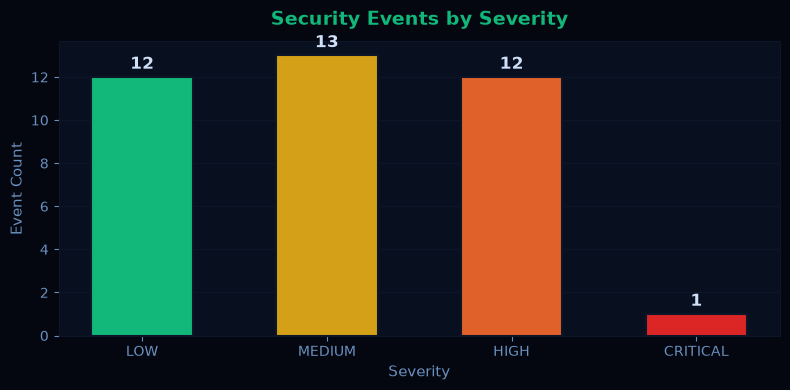

In [31]:
# ── Chart 1: Events by Severity ──────────────────────────────────────────
severity_order  = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
severity_colors = ["#12b87a", "#d4a017", "#e0622a", "#dc2626"]
counts = df["severity"].value_counts().reindex(severity_order, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor("#04070f")
ax.set_facecolor("#080f1e")

bars = ax.bar(severity_order, counts.values, color=severity_colors,
              edgecolor="#0c1628", linewidth=1.5, width=0.55)

for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            str(count), ha="center", va="bottom",
            color="#cfe0f8", fontsize=12, fontweight="bold")

ax.set_title("Security Events by Severity", color="#12b87a",
             fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Severity", color="#6a90c0", fontsize=11)
ax.set_ylabel("Event Count", color="#6a90c0", fontsize=11)
ax.tick_params(colors="#6a90c0")
for spine in ax.spines.values():
    spine.set_edgecolor("#0c1628")
ax.yaxis.grid(True, color="#0c1628", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

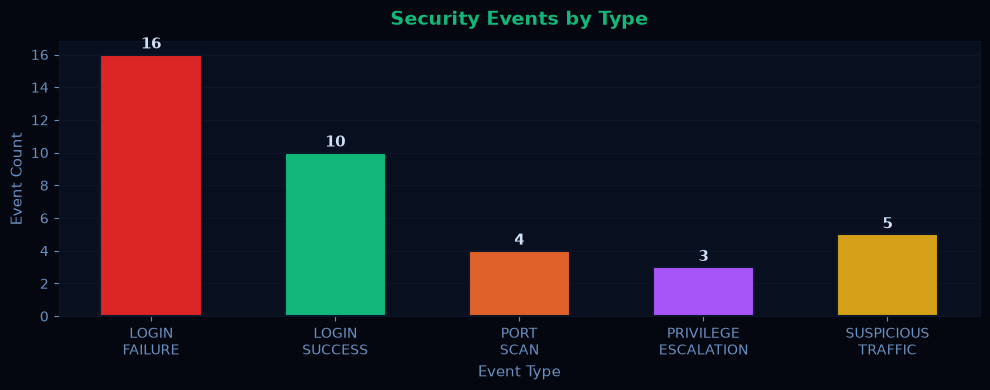

In [32]:
# ── Chart 2: Events by Type ───────────────────────────────────────────────
type_order = ["LOGIN_FAILURE", "LOGIN_SUCCESS", "PORT_SCAN",
              "PRIVILEGE_ESCALATION", "SUSPICIOUS_TRAFFIC"]
type_colors = ["#dc2626", "#12b87a", "#e0622a", "#a855f7", "#d4a017"]
type_counts = df["event_type"].value_counts().reindex(type_order, fill_value=0)
type_labels  = [t.replace("_", "\n") for t in type_order]

fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor("#04070f")
ax.set_facecolor("#080f1e")

bars = ax.bar(type_labels, type_counts.values, color=type_colors,
              edgecolor="#0c1628", linewidth=1.5, width=0.55)

for bar, count in zip(bars, type_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            str(count), ha="center", va="bottom",
            color="#cfe0f8", fontsize=11, fontweight="bold")

ax.set_title("Security Events by Type", color="#12b87a",
             fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Event Type", color="#6a90c0", fontsize=11)
ax.set_ylabel("Event Count", color="#6a90c0", fontsize=11)
ax.tick_params(colors="#6a90c0")
for spine in ax.spines.values():
    spine.set_edgecolor("#0c1628")
ax.yaxis.grid(True, color="#0c1628", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

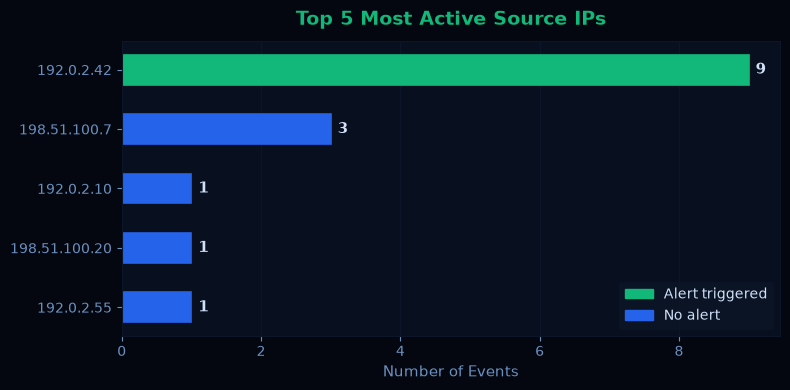

In [33]:
# ── Chart 3: Top 5 Most Active Source IPs ────────────────────────────────
top_ips = df["source_ip"].value_counts().head(5)

fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor("#04070f")
ax.set_facecolor("#080f1e")

bars = ax.barh(top_ips.index[::-1], top_ips.values[::-1],
               color="#2563eb", edgecolor="#0c1628", linewidth=1.2, height=0.5)

# Highlight the alert IP in emerald
alert_ips = {a["source_ip"] for a in alerts}
for bar, ip in zip(bars, top_ips.index[::-1]):
    color = "#12b87a" if ip in alert_ips else "#2563eb"
    bar.set_color(color)
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            str(int(bar.get_width())), va="center",
            color="#cfe0f8", fontsize=11, fontweight="bold")

ax.set_title("Top 5 Most Active Source IPs", color="#12b87a",
             fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Number of Events", color="#6a90c0", fontsize=11)
ax.tick_params(colors="#6a90c0")
for spine in ax.spines.values():
    spine.set_edgecolor("#0c1628")
ax.xaxis.grid(True, color="#0c1628", linewidth=0.8)
ax.set_axisbelow(True)

legend_patches = [
    mpatches.Patch(color="#12b87a", label="Alert triggered"),
    mpatches.Patch(color="#2563eb", label="No alert"),
]
ax.legend(handles=legend_patches, facecolor="#0c1628",
          labelcolor="#cfe0f8", edgecolor="#0c1628", fontsize=10)

plt.tight_layout()
plt.show()

---
## 10. Conclusion

SentinelX demonstrates a working cybersecurity threat detection system built entirely in Python with no external services.

| Component | What it demonstrates |
|---|---|
| Synthetic data generation | Realistic security event simulation using RFC 5737 IPs |
| Brute-force detection | Time-windowed, IP-grouped detection rule |
| Configurable rules | Threshold and window adjustable without code changes |
| Input validation | Safe filtering with error handling for invalid values |
| Data analysis | Pandas DataFrame operations (filter, group, sort) |
| Visualisation | Matplotlib charts matching the live Java dashboard |

The detection rule correctly:
- **Fires** on `192.0.2.42` (6 failures within 9 minutes — above threshold)
- **Does not fire** on `198.51.100.7` (3 failures — below threshold)
- **Ignores** the 2 older failures from `192.0.2.42` at 29–30 minutes ago (outside window)
- **Ignores** all successful logins entirely

---
*Gunjan Saini — IBM SkillsBuild Cybersecurity Bootcamp — October 2026 (BharatCares)*